# BTC/USDT 6-Hour-Ahead (12-Bar) Magnitude Regression - LSTM / Bi-LSTM

Predict the signed percent move `y_reg = (open[t+12] - open[t]) / open[t] * 100`
using a recurrent (LSTM / Bi-LSTM) model over a *sequence* of past bars,
instead of the flat feature vector used by the LightGBM notebooks.

Reuses the already-computed, leakage-safe feature set from
`./data/processed_dataset_target_lag12.csv` (same 72 features and target
alignment as `model_h12.ipynb` - each row's features only use information
available through the previous bar).

**Hyperparameter tuning**: Optuna (TPE sampler + median pruning) searches
over the sequence lookback length, LSTM width/depth, LSTM vs Bi-LSTM,
dropout, learning rate, weight decay and batch size, using validation MSE
as the objective.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
print("device:", DEVICE)

device: mps


## 1. Load precomputed features + target

In [2]:
DATA_PATH = "./data/processed_dataset_target_lag12.csv"

dataset = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)
dataset = dataset.sort_index()

feature_cols = [c for c in dataset.columns if c != "y_reg"]
print("rows:", len(dataset), " features:", len(feature_cols))
print(dataset.index.min(), "->", dataset.index.max())
dataset[feature_cols + ["y_reg"]].tail()

rows: 52396  features: 72
2023-09-06 04:00:00+00:00 -> 2026-09-01 17:30:00+00:00


,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_6,ret_lag_12,ret_lag_24,ret_lag_48,ret_lag_96,ret_mean_6,ret_std_6,...,roc_12,roc_24,winrate_10,winrate_20,winrate_50,hour_sin,hour_cos,dow_sin,dow_cos,y_reg
bar_open_time_utc,,,,,,,,,,,,,,,,,,,,,
2026-09-01 15:30:00+00:00,-0.003830,-0.005033,-0.002601,-0.001601,-0.000797,-0.007786,-0.007596,-0.011777,-0.000267,0.002423,...,-0.000797,-0.007756,0.5,0.45,0.52,-0.707107,-0.707107,0.781831,0.62349,-0.873940
2026-09-01 16:00:00+00:00,0.000640,-0.003190,-0.004393,-0.001090,0.000052,-0.009706,-0.008452,-0.011542,-0.000182,0.002449,...,0.000052,-0.009659,0.5,0.45,0.52,-0.793353,-0.608761,0.781831,0.62349,-0.908314
2026-09-01 16:30:00+00:00,-0.003805,-0.003165,-0.006995,-0.003411,-0.004918,-0.015422,-0.013107,-0.018136,-0.000569,0.002847,...,-0.004906,-0.015304,0.5,0.45,0.52,-0.866025,-0.500000,0.781831,0.62349,-0.709982
2026-09-01 17:00:00+00:00,-0.000349,-0.004155,-0.003515,-0.006115,-0.005573,-0.014472,-0.013359,-0.022200,-0.001019,0.002482,...,-0.005558,-0.014367,0.4,0.45,0.50,-0.923880,-0.382683,0.781831,0.62349,-0.414957
2026-09-01 17:30:00+00:00,-0.001058,-0.001408,-0.005213,-0.009607,-0.006368,-0.018904,-0.013077,-0.018238,-0.001601,0.001837,...,-0.006348,-0.018727,0.4,0.40,0.48,-0.965926,-0.258819,0.781831,0.62349,-0.151070


## 2. Time-based split, scaling, and sequence windows

Chronological 70/15/15 split (same convention as the LightGBM notebooks).
Both features and target are standardized using **train-only** statistics
to avoid leakage into validation/test. Sequences are built with a
`MAX_LOOKBACK` of 96 bars (48h); the Optuna search tries shorter lookbacks
by slicing the most recent `L <= MAX_LOOKBACK` steps from each window, so
every trial is evaluated on identical split boundaries.

In [3]:
X_raw = dataset[feature_cols].values.astype(np.float32)
y_raw = dataset["y_reg"].values.astype(np.float32)
n = len(dataset)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

MAX_LOOKBACK = 96  # 96 * 30m = 48h of history available to the longest trial
valid_start = MAX_LOOKBACK - 1  # earliest index with a full-length window

feat_scaler = StandardScaler().fit(X_raw[valid_start:train_end])
X_scaled = feat_scaler.transform(X_raw).astype(np.float32)

y_mean, y_std = y_raw[valid_start:train_end].mean(), y_raw[valid_start:train_end].std()
y_scaled = ((y_raw - y_mean) / y_std).astype(np.float32)

train_positions = np.arange(valid_start, train_end)
val_positions = np.arange(train_end, val_end)
test_positions = np.arange(val_end, n)

print("train/val/test sequence counts:", len(train_positions), len(val_positions), len(test_positions))
print("y_reg train mean/std used for scaling:", round(float(y_mean), 5), round(float(y_std), 5))

train/val/test sequence counts: 36582 7859 7860
y_reg train mean/std used for scaling: 0.05778 1.21786


In [4]:
class SequenceDataset(Dataset):
    """Each sample: the last `lookback` scaled feature rows ending at `pos`, target y_scaled[pos]."""

    def __init__(self, X_scaled, y_scaled, positions, lookback):
        self.X = X_scaled
        self.y = y_scaled
        self.positions = positions
        self.lookback = lookback

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, idx):
        pos = self.positions[idx]
        seq = self.X[pos - self.lookback + 1: pos + 1]
        return torch.from_numpy(seq), torch.tensor(self.y[pos])

## 3. LSTM / Bi-LSTM regression model

In [5]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout, bidirectional):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional,
        )
        out_size = hidden_size * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(out_size, out_size // 2),
            nn.ReLU(),
            nn.Linear(out_size // 2, 1),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        last = out[:, -1, :]  # final timestep (both directions concatenated if bidirectional)
        return self.head(last).squeeze(-1)

## 4. Training loop with early stopping (+ Optuna pruning hook)

In [6]:
def train_model(params, max_epochs, patience, trial=None):
    lookback = params["lookback"]
    train_ds = SequenceDataset(X_scaled, y_scaled, train_positions, lookback)
    val_ds = SequenceDataset(X_scaled, y_scaled, val_positions, lookback)
    train_loader = DataLoader(train_ds, batch_size=params["batch_size"], shuffle=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)

    model = LSTMRegressor(
        input_size=len(feature_cols),
        hidden_size=params["hidden_size"],
        num_layers=params["num_layers"],
        dropout=params["dropout"],
        bidirectional=params["bidirectional"],
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    loss_fn = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                val_losses.append(loss_fn(pred, yb).item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if trial is not None:
            trial.report(val_loss, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if epochs_no_improve >= patience:
            break

    model.load_state_dict(best_state)
    return model, best_val_loss, history

## 5. Optuna hyperparameter search

Search space covers sequence lookback, LSTM width/depth, LSTM vs Bi-LSTM,
dropout, learning rate, weight decay and batch size. Each trial trains with
early stopping (patience=3, up to 12 epochs) and can be pruned early via
`MedianPruner` if its validation loss is trending worse than other trials
at the same epoch.

In [7]:
def objective(trial):
    params = {
        "lookback": trial.suggest_categorical("lookback", [24, 48, 96]),
        "hidden_size": trial.suggest_categorical("hidden_size", [32, 64, 128]),
        "num_layers": trial.suggest_int("num_layers", 1, 2),
        "bidirectional": trial.suggest_categorical("bidirectional", [False, True]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.4),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
    }
    _, best_val_loss, _ = train_model(params, max_epochs=12, patience=3, trial=trial)
    return best_val_loss


study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE),
    pruner=MedianPruner(n_warmup_steps=3),
)
study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Best val MSE (scaled):", study.best_value)
print("Best params:", study.best_params)

[I 2026-09-24 10:18:59,605] A new study created in memory with name: no-name-5daad6a2-05dc-46c0-b270-fe576c1f6cd1


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-09-24 10:19:32,299] Trial 0 finished with value: 1.2148274779319763 and parameters: {'lookback': 48, 'hidden_size': 32, 'num_layers': 1, 'bidirectional': False, 'dropout': 0.2832290311184182, 'lr': 0.00010994335574766199, 'weight_decay': 0.0008123245085588687, 'batch_size': 128}. Best is trial 0 with value: 1.2148274779319763.
[I 2026-09-24 10:20:38,197] Trial 1 finished with value: 1.2096008881926537 and parameters: {'lookback': 96, 'hidden_size': 32, 'num_layers': 2, 'bidirectional': True, 'dropout': 0.1465447373174767, 'lr': 0.000816845589476017, 'weight_decay': 0.0002267398652378039, 'batch_size': 256}. Best is trial 1 with value: 1.2096008881926537.
[I 2026-09-24 10:22:07,270] Trial 2 finished with value: 1.2426242679357529 and parameters: {'lookback': 96, 'hidden_size': 128, 'num_layers': 2, 'bidirectional': False, 'dropout': 0.039068845602553554, 'lr': 0.0023359635026261607, 'weight_decay': 2.091498132903561e-05, 'batch_size': 256}. Best is trial 1 with value: 1.20960088

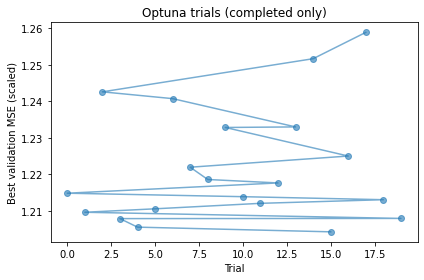

,number,value,params_batch_size,params_bidirectional,params_dropout,params_hidden_size,params_lookback,params_lr,params_num_layers,params_weight_decay
15,15,1.204235,256,False,0.328189,128,24,0.009381,2,0.000142
4,4,1.205521,256,False,0.217078,64,48,0.000191,2,0.000255
3,3,1.207859,256,True,0.310053,32,48,0.007568,2,0.000484
19,19,1.207912,256,False,0.089177,128,24,0.000167,2,0.000150
1,1,1.209601,256,True,0.146545,32,96,0.000817,2,0.000227
5,5,1.210547,128,True,0.046348,32,24,0.005324,2,0.000074
11,11,1.212050,256,False,0.366207,64,48,0.009635,2,0.000969
18,18,1.213044,128,False,0.338216,128,24,0.003769,2,0.000053
10,10,1.213873,256,False,0.201012,64,48,0.000120,1,0.000012
0,0,1.214827,128,False,0.283229,32,48,0.000110,1,0.000812


In [10]:
trials_df = study.trials_dataframe()
trials_df = trials_df[trials_df["state"] == "COMPLETE"].sort_values("value")

plt.figure(figsize=(6, 4))
plt.plot(trials_df["number"], trials_df["value"], "o-", alpha=0.6)
plt.xlabel("Trial")
plt.ylabel("Best validation MSE (scaled)")
plt.title("Optuna trials (completed only)")
plt.tight_layout()
plt.show()

trials_df[["number", "value"] + [c for c in trials_df.columns if c.startswith("params_")]].head(10)

## 6. Retrain best configuration (longer, more patience) and evaluate on test set

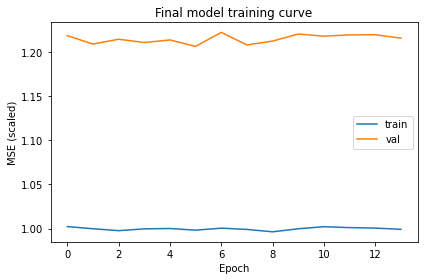

In [11]:
best_params = study.best_params
final_model, final_val_loss, history = train_model(best_params, max_epochs=60, patience=8)

plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("Final model training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
lookback = best_params["lookback"]
test_ds = SequenceDataset(X_scaled, y_scaled, test_positions, lookback)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)

final_model.eval()
preds_scaled, actuals_scaled = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        pred = final_model(xb).cpu().numpy()
        preds_scaled.append(pred)
        actuals_scaled.append(yb.numpy())

preds_scaled = np.concatenate(preds_scaled)
actuals_scaled = np.concatenate(actuals_scaled)

# invert the target standardization back to % units
preds_pct = preds_scaled * y_std + y_mean
actuals_pct = actuals_scaled * y_std + y_mean

mae = mean_absolute_error(actuals_pct, preds_pct)
rmse = mean_squared_error(actuals_pct, preds_pct) ** 0.5
naive_mae = mean_absolute_error(actuals_pct, np.zeros_like(actuals_pct))
ss_res = np.sum((actuals_pct - preds_pct) ** 2)
ss_tot = np.sum((actuals_pct - actuals_pct.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
dir_acc = ((preds_pct > 0).astype(int) == (actuals_pct > 0).astype(int)).mean()

print(f"Best params: {best_params}")
print(f"Test MAE:  {mae:.4f}%")
print(f"Test RMSE: {rmse:.4f}%")
print(f"Naive (predict 0%) MAE: {naive_mae:.4f}%")
print(f"R^2: {r2:.4f}")
print(f"Directional accuracy (sign of predicted vs actual move): {dir_acc:.4f}")

Best params: {'lookback': 24, 'hidden_size': 128, 'num_layers': 2, 'bidirectional': False, 'dropout': 0.32818890127467676, 'lr': 0.00938142690093663, 'weight_decay': 0.00014208731121675026, 'batch_size': 256}
Test MAE:  0.6721%
Test RMSE: 0.9734%
Naive (predict 0%) MAE: 0.6725%
R^2: -0.0006
Directional accuracy (sign of predicted vs actual move): 0.5125


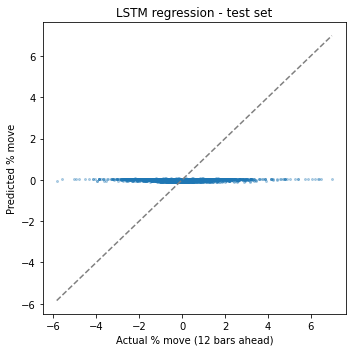

In [13]:
plt.figure(figsize=(5, 5))
plt.scatter(actuals_pct, preds_pct, s=4, alpha=0.3)
lims = [min(actuals_pct.min(), preds_pct.min()), max(actuals_pct.max(), preds_pct.max())]
plt.plot(lims, lims, "--", color="gray")
plt.xlabel("Actual % move (12 bars ahead)")
plt.ylabel("Predicted % move")
plt.title("LSTM regression - test set")
plt.tight_layout()
plt.show()

## 7. Discussion

- Optuna searches the sequence lookback jointly with architecture and
  optimization hyperparameters, which is the recurrent-model analogue of
  "you can decide the appropriate timestep of previous data" - the model
  itself picks how much history is useful rather than fixing it upfront.
- Compare the LSTM's test MAE/RMSE/directional-accuracy directly against
  the LightGBM regressor's numbers from `model_h12.ipynb` on the same
  `y_reg` target and the same chronological test window - if the LSTM
  doesn't clearly beat the "always predict 0%" naive baseline and the
  LightGBM regressor, that itself is informative: it suggests the 6-hour
  BTC magnitude is dominated by noise a recurrent model can't extract more
  signal from than a tree ensemble on the same engineered features, rather
  than the LSTM being under-tuned.
- Bidirectional access to "future" timesteps within a training window is
  still legitimate here (no leakage): bidirectionality only lets the model
  use both directions of the *input sequence* (already-lagged features up
  to bar t-1), never the target bar itself.